# 01 — Compréhension des données, nettoyage et analyse exploratoire (EDA)

**Projet :** système de détection d'intrusions réseau (NIDS) sur le jeu **UNSW-NB15**.

| Élément | Valeur |
|---|---|
| Source | UNSW Canberra — Moustafa & Slay (2015), thèse de N. Moustafa (2017) |
| Volume brut | 4 fichiers CSV, **2 540 047 flux**, **49 colonnes** |
| Cibles | `label` (0 normal / 1 attaque) et `attack_cat` (10 catégories) |

**Rôle de ce notebook :** comprendre la structure des données, mesurer leur qualité (valeurs manquantes,
codages incohérents, doublons), les nettoyer, puis explorer les distributions et vérifier par des
**tests statistiques** quelles variables distinguent le trafic normal des attaques. Ces constats
justifient les choix de prétraitement du notebook 02.

In [1]:
# Configuration : le notebook s'exécute depuis notebooks/, on ajoute la racine du dépôt au chemin
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src import config as C
from src import visualization as V
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
print('Racine du projet :', ROOT.name)

Racine du projet : Network-Intrusion-Detection-System


## 1. Chargement et échantillonnage stratifié

**Pourquoi échantillonner ?** Le jeu complet (2,54 M lignes, 87 % de trafic normal) est trop lourd pour
comparer 15 modèles avec validation croisée, et la classe rare *Worms* ne compte que 174 flux.
On construit un **échantillon stratifié reproductible** (`random_state=42`) : 60 000 flux normaux tirés
uniformément et **jusqu'à 8 000 flux par catégorie d'attaque** — toutes les lignes des classes rares sont gardées.

Le code est dans `src/preprocessing.py` (`load_raw_sample`) et `src/prepare_data.py`. S'il a déjà été
exécuté, on relit simplement les fichiers produits.

In [2]:
from src import prepare_data
if not C.CLEAN_FILE.exists():
    prepare_data.main()          # lecture des 4 CSV bruts (~15 s), échantillonnage, nettoyage, split
meta = json.loads(C.SPLIT_META_FILE.read_text(encoding='utf-8'))
rs = meta['raw_stats']
print(f"Lignes par fichier : {rs['files']}")
print(f"Total brut : {rs['full_total']:,} flux  |  échantillon : {rs['sample_total']:,}")
full = pd.Series(rs['full_counts']).reindex(C.ATTACK_CATEGORIES)
sample = pd.Series(rs['sample_counts']).reindex(C.ATTACK_CATEGORIES)
display(pd.DataFrame({'jeu complet': full, '% complet': (100 * full / full.sum()).round(3),
                      'échantillon': sample, '% échantillon': (100 * sample / sample.sum()).round(2)}))

Lignes par fichier : {'UNSW-NB15_1.csv': 700001, 'UNSW-NB15_2.csv': 700001, 'UNSW-NB15_3.csv': 700001, 'UNSW-NB15_4.csv': 440044}
Total brut : 2,540,047 flux  |  échantillon : 106,691


,jeu complet,% complet,échantillon,% échantillon
Normal,2218764,87.351,60000,56.24
Generic,215481,8.483,8000,7.50
Exploits,44525,1.753,8000,7.50
Fuzzers,24246,0.955,8000,7.50
DoS,16353,0.644,8000,7.50
Reconnaissance,13987,0.551,8000,7.50
Analysis,2677,0.105,2677,2.51
Backdoor,2329,0.092,2329,2.18
Shellcode,1511,0.059,1511,1.42
Worms,174,0.007,174,0.16


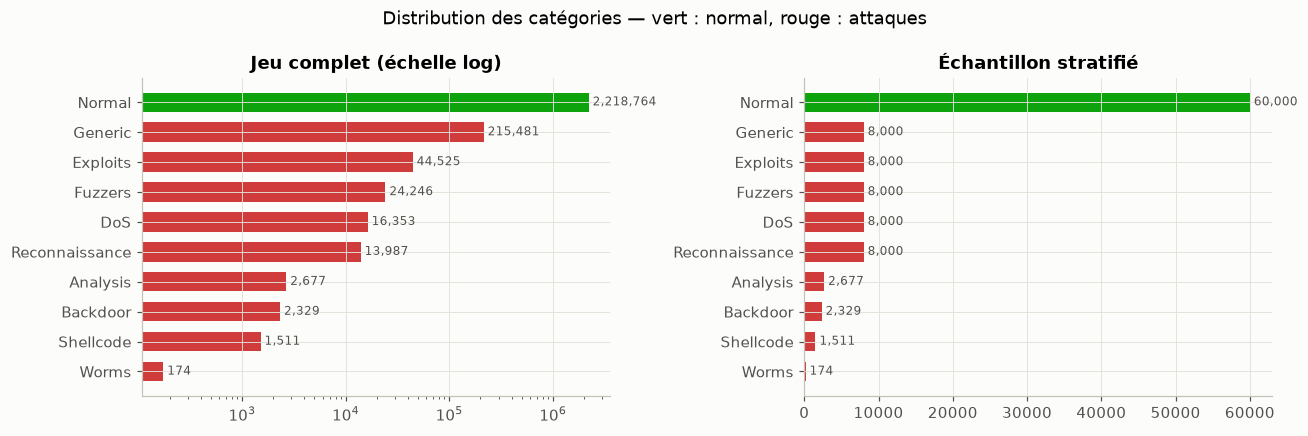

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
V.barh(axes[0], full.index, full.values, color=V.class_colors(full.index), fmt='{:,.0f}')
axes[0].set_xscale('log'); axes[0].set_title('Jeu complet (échelle log)')
V.barh(axes[1], sample.index, sample.values, color=V.class_colors(sample.index), fmt='{:,.0f}')
axes[1].set_title('Échantillon stratifié')
fig.suptitle('Distribution des catégories — vert : normal, rouge : attaques'); plt.tight_layout()
V.save(fig, '01_class_distribution'); plt.show()

## 2. Qualité des données brutes

On inspecte l'échantillon **avant** nettoyage. Points connus de UNSW-NB15 que l'on vérifie :
- `attack_cat` vide pour le trafic normal ;
- `ct_flw_http_mthd`, `is_ftp_login` vides dans les fichiers 2 à 4 (flux non HTTP/FTP) ;
- `ct_ftp_cmd` contenant la chaîne `' '` ;
- ports source/destination parfois **hexadécimaux** (`0x000b`) ou `'-'` ;
- espaces parasites (`' Fuzzers'`) et doubles libellés (`Backdoor` / `Backdoors`).

,% manquant (brut)
is_ftp_login,66.72
ct_ftp_cmd,66.72
ct_flw_http_mthd,60.98
attack_cat,56.24


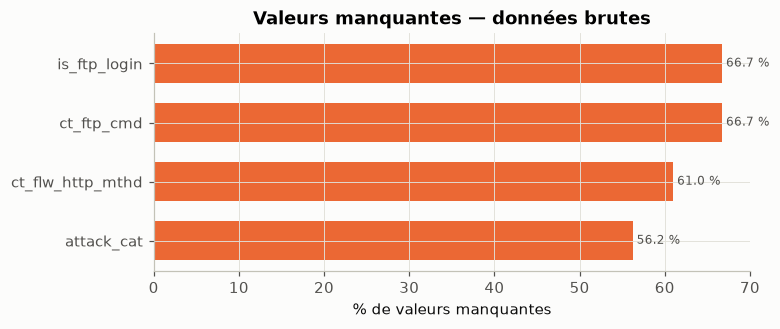

Ports hexadécimaux : {'sport': 0, 'dsport': 14} | libellés attack_cat bruts : <ArrowStringArray>
['Generic', ' Reconnaissance ', ' Fuzzers ', 'DoS', 'Exploits', 'Analysis', ' Fuzzers', ' Shellcode ', 'Backdoor', 'Reconnaissance', 'Backdoors', 'Shellcode']
Length: 12, dtype: str


In [4]:
raw = pd.read_csv(C.SAMPLE_FILE, low_memory=False)
blank = raw.apply(lambda s: s.isna() | s.astype(str).str.strip().eq(''))
miss = (blank.mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
display(miss.round(2).to_frame('% manquant (brut)'))
fig, ax = plt.subplots(figsize=(7, 2.8))
V.barh(ax, miss.index, miss.values, color=V.SERIES[1], fmt='{:.1f} %')
ax.set_xlabel('% de valeurs manquantes'); ax.set_title('Valeurs manquantes — données brutes')
V.save(fig, '01_missing_values'); plt.show()
hexa = raw[['sport', 'dsport']].astype(str).apply(lambda s: s.str.startswith('0x').sum())
print('Ports hexadécimaux :', hexa.to_dict(), '| libellés attack_cat bruts :', raw['attack_cat'].dropna().unique()[:12])

## 3. Nettoyage

Fonction `clean_dataframe` (identique pour le CSV et pour les flux extraits d'un PCAP — voir notebook 07) :

| Problème | Traitement | Justification |
|---|---|---|
| `attack_cat` vide | → `Normal` | la ligne est normale (`label = 0`) |
| `ct_flw_http_mthd`, `is_ftp_login`, `ct_ftp_cmd` vides | → 0 | absence d'événement HTTP/FTP, pas une donnée inconnue |
| `is_ftp_login` > 1 | → 1 | variable binaire par définition (Alg. 3.5) |
| ports hexadécimaux / `-` | conversion entière / NaN | identifiants, non utilisés comme features |
| catégories avec espaces / casse | normalisation | éviter des modalités fantômes |
| doublons exacts (features + cible) | suppression | éviter un biais d'apprentissage et une fuite train/test |

Les **identifiants** (`srcip`, `sport`, `dstip`, `dsport`, `stime`, `ltime`) et les **numéros de séquence
initiaux** (`stcpb`, `dtcpb`, aléatoires par construction) sont exclus des features : un modèle qui apprend
les adresses du banc de test ne généralise pas.

In [5]:
rep = meta['cleaning_report']
display(pd.Series({k: v for k, v in rep.items() if not isinstance(v, dict)}, name='valeur').to_frame())
df = pd.read_csv(C.CLEAN_FILE, low_memory=False)
print(f"Jeu nettoyé : {df.shape[0]:,} lignes × {df.shape[1]} colonnes | features modèle : {len(C.FEATURES)}")
print('Valeurs manquantes restantes dans les features :', int(df[C.FEATURES].isna().sum().sum()))
print(f"Vecteurs identiques étiquetés différemment : {rep['conflicting_vectors']:,} "
      "(bruit d'étiquetage connu de UNSW-NB15 — borne la performance multi-classe)")

,valeur
rows_in,106691
missing_ct_flw_http_mthd,65059
missing_is_ftp_login,71187
missing_ct_ftp_cmd,71187
is_ftp_login_gt1,16
inf_values,0
incoherent_labels,0
duplicates_removed,15402
conflicting_vectors,8053
rows_out,91289


Jeu nettoyé : 91,289 lignes × 49 colonnes | features modèle : 39
Valeurs manquantes restantes dans les features : 0
Vecteurs identiques étiquetés différemment : 8,053 (bruit d'étiquetage connu de UNSW-NB15 — borne la performance multi-classe)


## 4. Statistiques descriptives
Tendance centrale (moyenne, médiane), dispersion (écart-type, IQR) et forme (asymétrie, aplatissement).

In [6]:
desc = df[C.NUMERIC_FEATURES].describe().T
desc['asymétrie'] = df[C.NUMERIC_FEATURES].skew(); desc['aplatissement'] = df[C.NUMERIC_FEATURES].kurt()
display(desc.round(3))
display(df[C.CATEGORICAL_FEATURES + ['attack_cat']].describe().T)

,count,mean,std,min,25%,50%,75%,max,asymétrie,aplatissement
dur,91289.0,1.003000e+00,4.960000e+00,0.0,0.001,0.026,0.627,5.999900e+01,9.257,93.221
sbytes,91289.0,6.927145e+03,1.326490e+05,28.0,200.000,882.000,2934.000,1.435577e+07,68.463,5432.400
dbytes,91289.0,3.078753e+04,1.829108e+05,0.0,162.000,382.000,10168.000,1.465555e+07,25.352,1369.006
sttl,91289.0,1.070420e+02,1.033220e+02,0.0,31.000,31.000,254.000,2.550000e+02,0.705,-1.475
dttl,91289.0,6.638400e+01,9.258900e+01,0.0,29.000,29.000,29.000,2.540000e+02,1.463,0.251
sloss,91289.0,5.651000e+00,5.037200e+01,0.0,0.000,2.000,7.000,5.319000e+03,65.183,5051.024
dloss,91289.0,1.383900e+01,6.592600e+01,0.0,0.000,1.000,8.000,5.484000e+03,27.333,1563.704
sload,91289.0,4.503865e+07,1.578373e+08,0.0,21864.709,543255.812,2366688.250,5.988000e+09,9.659,166.633
dload,91289.0,1.858345e+06,3.822878e+06,0.0,1939.954,70961.492,978540.750,2.236848e+07,2.400,4.763
spkts,91289.0,3.048100e+01,1.149070e+02,1.0,2.000,10.000,36.000,1.064600e+04,44.768,3004.631


,count,unique,top,freq
proto,91289,133,tcp,55950
state,91289,10,fin,55437
service,91289,13,-,52966
attack_cat,91289,10,Normal,57279


**Lecture :** la plupart des variables de volume (`sbytes`, `dbytes`, `sload`, `dload`, `sjit`…) ont une
asymétrie > 10 et une moyenne très supérieure à la médiane : distributions à **queue lourde**. On travaillera
en échelle `log1p` pour les visualiser et les modéliser.

## 5. Distributions des variables numériques (histogrammes + KDE)

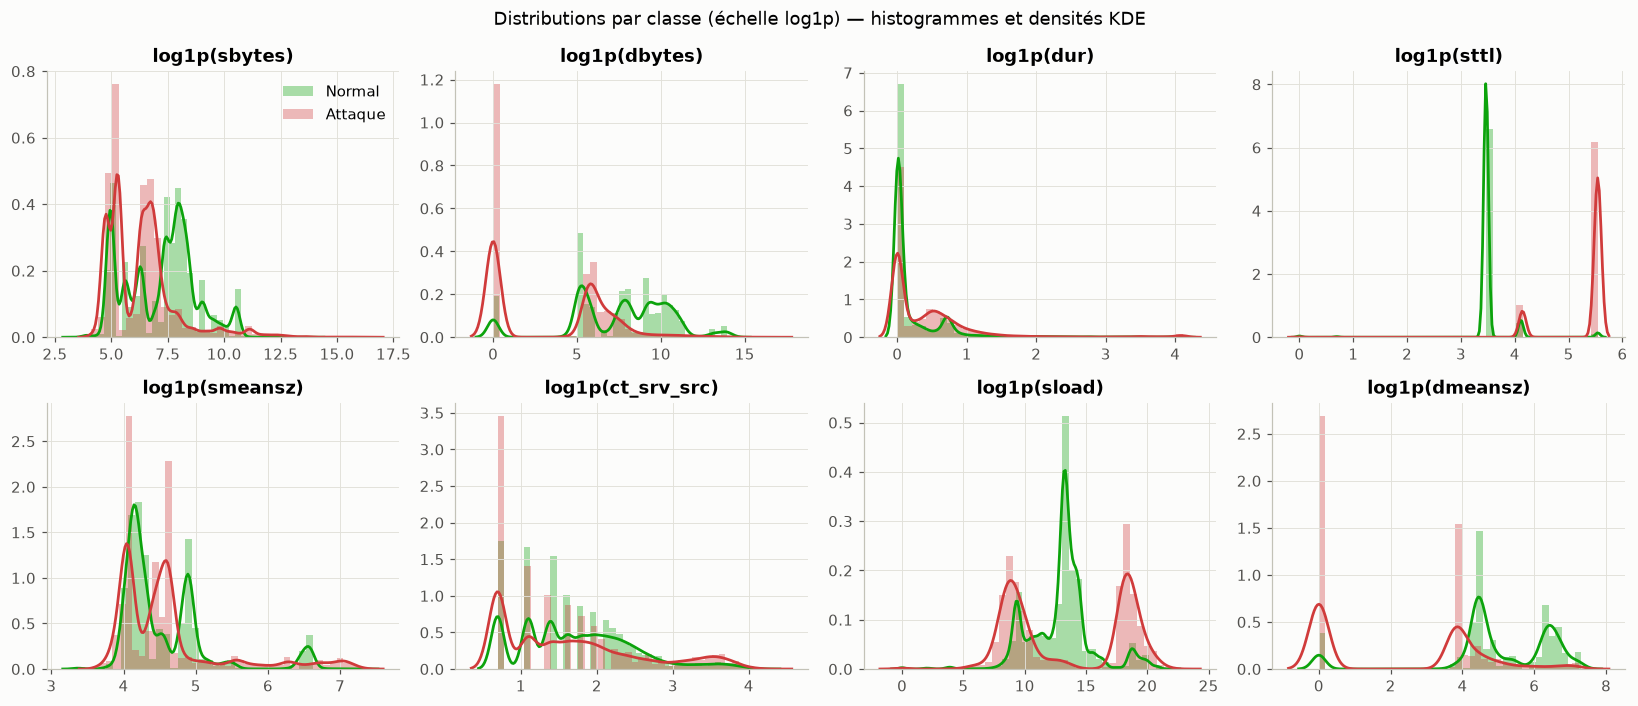

In [7]:
key = ['sbytes', 'dbytes', 'dur', 'sttl', 'smeansz', 'ct_srv_src', 'sload', 'dmeansz']
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.ravel(), key):
    for lab, col, name in ((0, V.NORMAL, 'Normal'), (1, V.ATTACK, 'Attaque')):
        x = np.log1p(df.loc[df.label == lab, c].clip(lower=0))
        sns.histplot(x, bins=40, stat='density', color=col, alpha=0.35, ax=ax, label=name, edgecolor=None)
        if x.nunique() > 2:
            sns.kdeplot(x, color=col, ax=ax, linewidth=1.8, warn_singular=False)
    ax.set_title(f'log1p({c})'); ax.set_xlabel(''); ax.set_ylabel('')
axes[0, 0].legend()
fig.suptitle('Distributions par classe (échelle log1p) — histogrammes et densités KDE'); plt.tight_layout()
V.save(fig, '01_numeric_distributions'); plt.show()

**Observations :**
- `sttl` est quasi binaire : 31 (normal) vs 254/62 (attaques). C'est la variable la plus séparatrice, mais
  c'est en partie un **artefact de la topologie du banc de test** (thèse §3.3) — nous évaluerons un profil
  de modèle « portable » sans TTL.
- Les attaques ont des `dbytes` nuls bien plus souvent (flux unidirectionnels, état `INT`).
- `ct_srv_src` (connexions répétées vers le même service) est élevé pour *Generic* (rafales DNS).

## 6. Fréquences des variables catégorielles

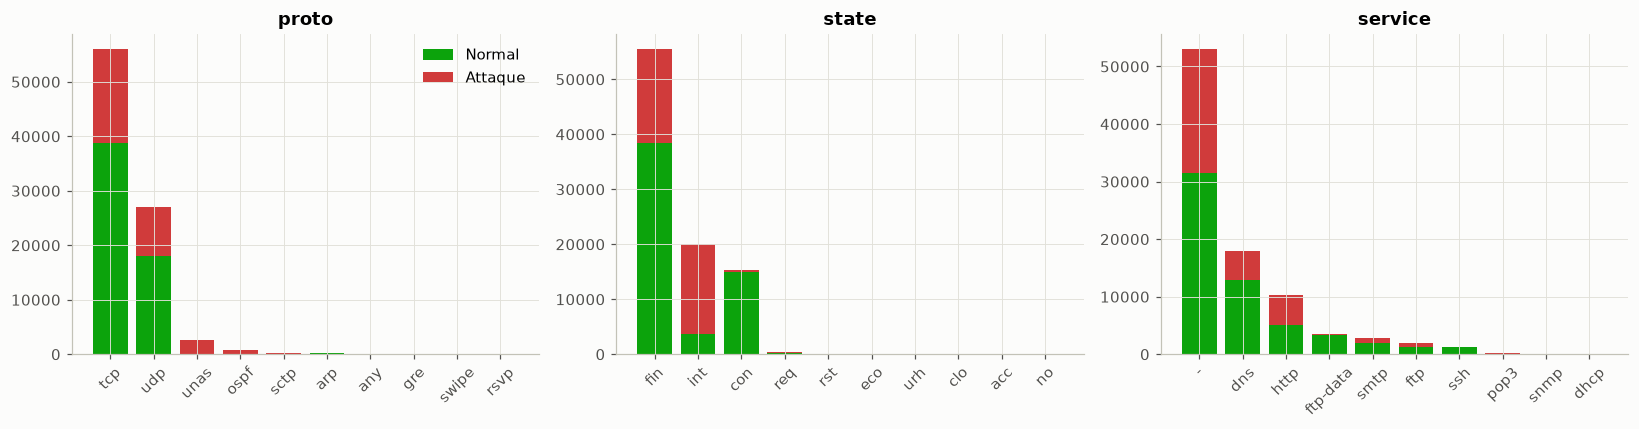

proto,tcp,udp,unas,ospf,sctp,arp
attack_cat,,,,,,
Analysis,456,0,578,71,24,0
Backdoor,319,34,509,146,65,0
DoS,1628,234,539,148,70,0
Exploits,4846,141,472,126,64,0
Fuzzers,4949,1806,261,66,18,0
Generic,117,4919,22,4,3,0
Normal,38777,18104,0,127,0,251
Reconnaissance,3958,1057,322,103,52,0
Shellcode,750,706,0,0,0,0


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, C.CATEGORICAL_FEATURES):
    top = df[c].value_counts().index[:10]
    ct = pd.crosstab(df[c], df['label']).reindex(top)
    ax.bar(ct.index.astype(str), ct[0], color=V.NORMAL, label='Normal')
    ax.bar(ct.index.astype(str), ct[1], bottom=ct[0], color=V.ATTACK, label='Attaque')
    ax.set_title(c); ax.tick_params(axis='x', rotation=45)
axes[0].legend(); plt.tight_layout(); V.save(fig, '01_categorical_frequencies'); plt.show()
display(pd.crosstab(df['attack_cat'], df['proto']).loc[:, lambda t: t.sum().nlargest(6).index])

## 7. Boîtes à moustaches par catégorie d'attaque

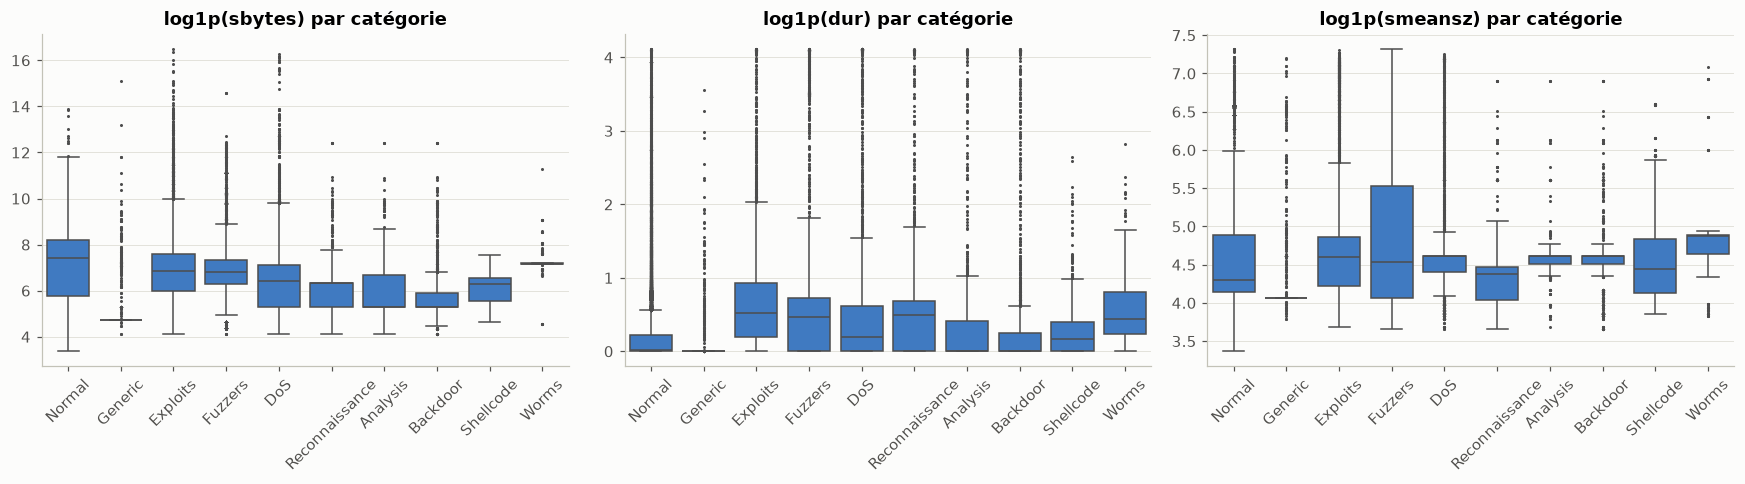

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ['sbytes', 'dur', 'smeansz']):
    d = df.assign(v=np.log1p(df[c].clip(lower=0)))
    order = C.ATTACK_CATEGORIES
    sns.boxplot(data=d, x='attack_cat', y='v', order=order, ax=ax, color=V.SERIES[0], fliersize=1, linewidth=1)
    ax.set_title(f'log1p({c}) par catégorie'); ax.set_xlabel(''); ax.set_ylabel(''); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); V.save(fig, '01_boxplots_by_category'); plt.show()

## 8. Corrélations (Spearman)
Spearman (sur les rangs) est préféré à Pearson : il capte les relations monotones et résiste aux queues lourdes.

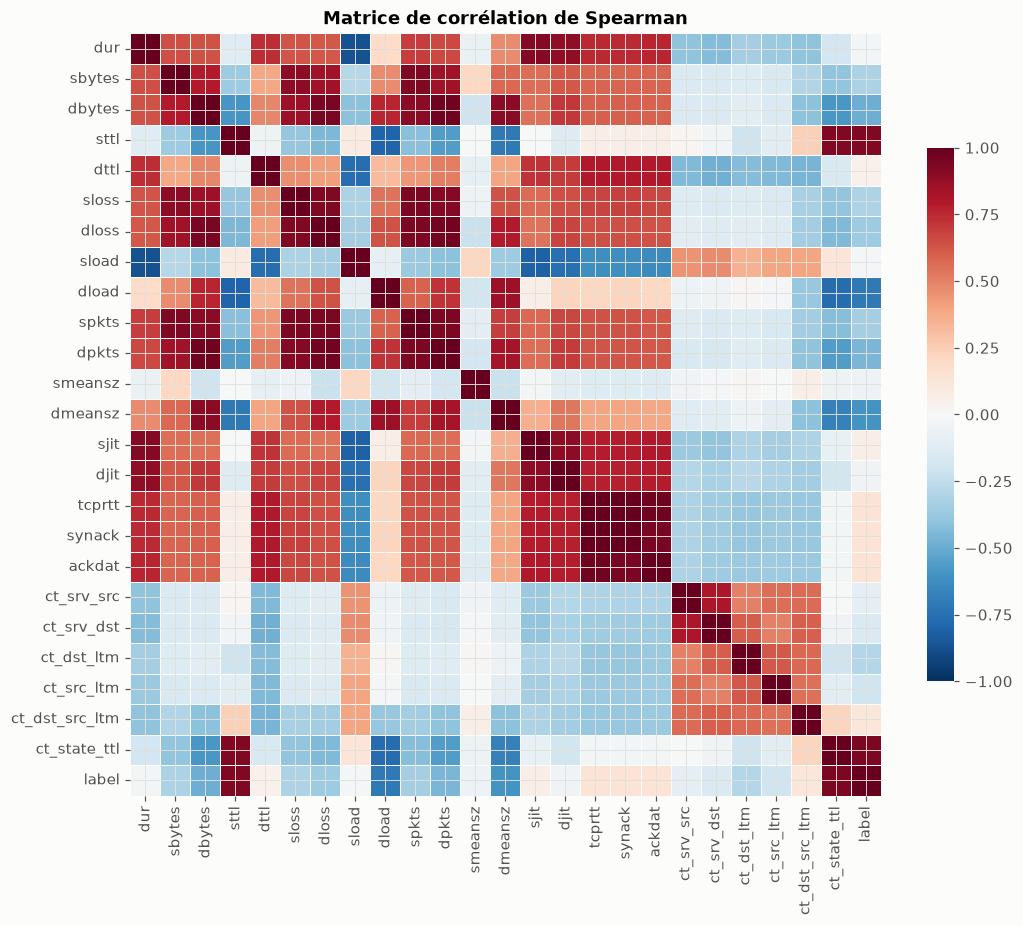

,,ρ
tcprtt,synack,0.992
dbytes,dpkts,0.975
tcprtt,ackdat,0.973
dloss,dpkts,0.967
synack,ackdat,0.953
dbytes,dloss,0.948
spkts,dpkts,0.944
ct_state_ttl,label,0.941
sloss,spkts,0.939
dloss,spkts,0.938


In [10]:
cols = ['dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'sload', 'dload', 'spkts', 'dpkts', 'smeansz',
        'dmeansz', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm',
        'ct_src_ltm', 'ct_dst_src_ltm', 'ct_state_ttl', 'label']
corr = df[cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=V.DIV_CMAP, vmin=-1, vmax=1, ax=ax, linewidths=0.4, linecolor='#fcfcfb', cbar_kws={'shrink': 0.7})
ax.set_title('Matrice de corrélation de Spearman'); V.save(fig, '01_spearman_heatmap'); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=np.abs, ascending=False)
display(pairs.head(12).round(3).to_frame('ρ'))

**Lecture :** blocs très corrélés (`sbytes`–`spkts`–`sloss`, `dbytes`–`dpkts`–`dloss`, `synack`–`ackdat`–`tcprtt`,
famille `ct_*`). La redondance n'est pas grave pour les arbres mais déstabilise les modèles linéaires et
Naïve Bayes (hypothèse d'indépendance) : le pipeline retire une variable de chaque paire |r| > 0,95 (ajusté sur le train).

## 9. Tests statistiques

Six familles de tests, chacune **justifiée** par la nature des variables (code : `src/evaluation/statistical_tests.py`).
Comme on réalise plusieurs dizaines de tests, les p-values sont corrigées par **Benjamini-Hochberg** (FDR 5 %) :
sans correction, on attendrait ≈ 5 % de faux positifs parmi les tests.

Les tests sont menés sur le **train uniquement** (le test reste intact pour l'évaluation finale).

In [11]:
from src.evaluation import statistical_tests as ST
train = pd.read_csv(C.TRAIN_FILE, low_memory=False)
num = C.NUMERIC_FEATURES

### 9.1 Normalité — Shapiro-Wilk et D'Agostino K²
*H₀ : la variable suit une loi normale.* Shapiro-Wilk est le test le plus puissant pour n ≤ 5 000 (on tire
4 000 observations : au-delà, le test rejette pour des écarts minimes). D'Agostino K² combine asymétrie et
aplatissement et confirme le résultat.

In [12]:
norm = ST.normality_tests(train, num)
display(norm[['feature', 'shapiro_W', 'shapiro_p_bh', 'dagostino_K2', 'skewness', 'normal_at_5pct']].round(4).head(15))
print(f"Normalité rejetée (p_BH < 0,05) pour {(~norm.normal_at_5pct).sum()} / {norm.shapiro_p.notna().sum()} variables testées.")

,feature,shapiro_W,shapiro_p_bh,dagostino_K2,skewness,normal_at_5pct
0,dur,0.1872,0.0,5665.9174,8.5696,False
1,sbytes,0.0157,0.0,12137.2841,44.5425,False
2,dbytes,0.1931,0.0,5369.4469,7.7241,False
3,sttl,0.6299,0.0,26677.8794,0.7002,False
4,dttl,0.5850,0.0,794.2824,1.4348,False
5,sloss,0.0290,0.0,12006.3563,43.2487,False
6,dloss,0.2404,0.0,5375.4401,7.6917,False
7,sload,0.3137,0.0,5055.0009,6.9647,False
8,dload,0.5416,0.0,1885.6233,2.4133,False
9,spkts,0.0950,0.0,11378.6549,37.3905,False


Normalité rejetée (p_BH < 0,05) pour 36 / 36 variables testées.


**Conséquence :** aucune variable n'est normale → on utilise des tests **non paramétriques** (Mann-Whitney, Kruskal-Wallis, Spearman) et une transformation `log1p` + standardisation dans le prétraitement.

### 9.2 Mann-Whitney U — numérique vs classe binaire
*H₀ : les distributions normal / attaque sont identiques.* Alternative non paramétrique au test t (deux groupes
indépendants, variables non normales). Avec n ≈ 73 000, presque tout est significatif : on rapporte donc la
**taille d'effet** r rang-bisériale (|r| > 0,5 : effet fort).

,feature,median_normal,median_attack,rank_biserial_r,effect_size,p_bh
0,sttl,31.0000,254.0000,0.9770,fort,0.0
1,ct_state_ttl,0.0000,1.0000,0.9729,fort,0.0
2,dload,669172.9375,1027.4745,-0.8470,fort,0.0
3,dmeansz,108.0000,44.0000,-0.7122,fort,0.0
4,dbytes,3080.0000,268.0000,-0.5742,fort,0.0
5,dpkts,18.0000,6.0000,-0.5416,fort,0.0
6,dloss,5.0000,1.0000,-0.4218,moyen,0.0
7,spkts,16.0000,10.0000,-0.3944,moyen,0.0
8,sbytes,1684.0000,564.0000,-0.3735,moyen,0.0
9,sloss,4.0000,1.0000,-0.3565,moyen,0.0


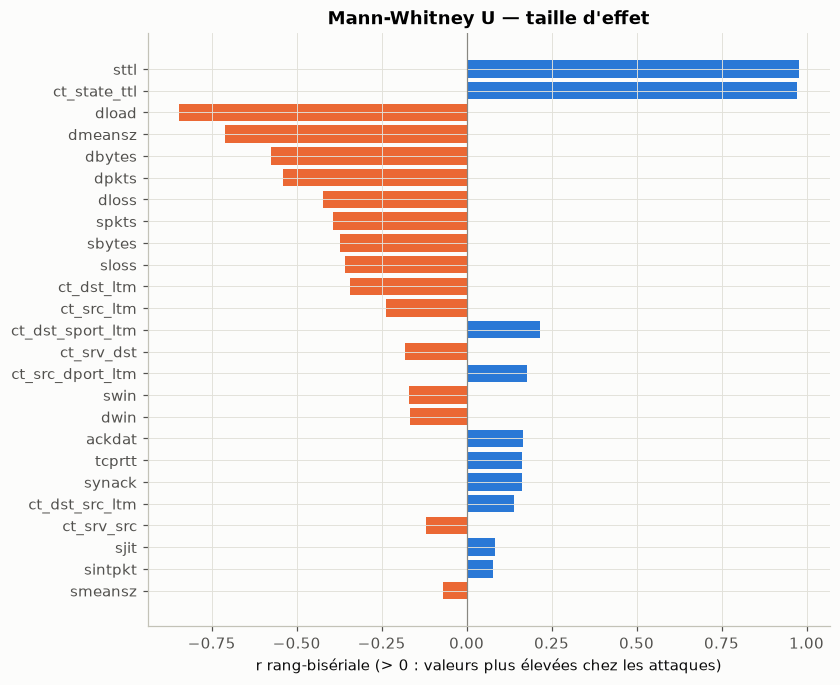

35 / 36 variables significatives après correction BH ; effet fort : 6


In [13]:
mw = ST.mann_whitney(train, num)
display(mw[['feature', 'median_normal', 'median_attack', 'rank_biserial_r', 'effect_size', 'p_bh']].head(15).round(4))
fig, ax = plt.subplots(figsize=(8, 7))
top = mw.head(25)
ax.barh(top.feature, top.rank_biserial_r, color=[V.SERIES[0] if r > 0 else V.SERIES[1] for r in top.rank_biserial_r])
ax.invert_yaxis(); ax.axvline(0, color='#898781', lw=0.8)
ax.set_xlabel('r rang-bisériale (> 0 : valeurs plus élevées chez les attaques)'); ax.set_title('Mann-Whitney U — taille d\'effet')
V.save(fig, '01_mann_whitney_effects'); plt.show()
print(f"{mw.significant.sum()} / {len(mw)} variables significatives après correction BH ; effet fort : {(mw.abs_effect > 0.5).sum()}")

### 9.3 Kruskal-Wallis — numérique vs 10 catégories
Généralisation non paramétrique de l'ANOVA à un facteur. Taille d'effet ε² = (H − k + 1)/(n − k).

In [14]:
kw = ST.kruskal_wallis(train, num)
display(kw.head(12).round(4))

,feature,H,p_value,epsilon_sq,p_bh,significant
0,ct_state_ttl,65655.2580,0.0,0.8990,0.0,True
1,sttl,63526.5873,0.0,0.8699,0.0,True
2,dload,38800.2962,0.0,0.5312,0.0,True
3,dmeansz,30327.8971,0.0,0.4152,0.0,True
4,ct_dst_sport_ltm,23990.6734,0.0,0.3284,0.0,True
5,ct_dst_ltm,22279.0682,0.0,0.3050,0.0,True
6,dbytes,21635.6182,0.0,0.2962,0.0,True
7,dpkts,20081.7019,0.0,0.2749,0.0,True
8,ct_srv_dst,19378.5216,0.0,0.2653,0.0,True
9,dttl,17776.3393,0.0,0.2433,0.0,True


### 9.4 Chi² d'indépendance + V de Cramér — catégoriel vs cible
*H₀ : la variable est indépendante de la cible.* Condition de validité : effectifs théoriques ≥ 5 → les modalités
trop rares pour l'atteindre (compte tenu de la plus petite classe, ex. Worms) sont regroupées dans « autre »
(colonne `pct_expected_lt5` = 0 % pour tous les tests). Le V de Cramér (0 à 1) mesure la force de l'association indépendamment de n.

In [15]:
chi = pd.concat([ST.chi2_tests(train, C.CATEGORICAL_FEATURES, 'label'), ST.chi2_tests(train, C.CATEGORICAL_FEATURES, 'attack_cat')])
display(chi.round(4))

,feature,target,chi2,dof,p_value,cramers_v,n_levels,pct_expected_lt5,p_bh
0,proto,label,11376.6465,130,0.0,0.3947,131,0.0,0.0
1,state,label,20479.3746,5,0.0,0.5295,6,0.0,0.0
2,service,label,3418.2263,11,0.0,0.2163,12,0.0,0.0
0,proto,attack_cat,39592.7580,18,0.0,0.5206,3,0.0,0.0
1,state,attack_cat,32086.0370,18,0.0,0.4700,3,0.0,0.0
2,service,attack_cat,29425.3669,36,0.0,0.3174,5,0.0,0.0


### 9.5 Corrélation de Spearman avec la cible

In [16]:
sp = ST.spearman_with_target(train, num)
display(sp.head(12).round(4))

,feature,spearman_rho,p_value,p_bh
0,ct_state_ttl,0.9406,0.0,0.0
1,sttl,0.9280,0.0,0.0
2,dload,-0.7133,0.0,0.0
3,dmeansz,-0.6001,0.0,0.0
4,dbytes,-0.4838,0.0,0.0
5,dpkts,-0.4569,0.0,0.0
6,dloss,-0.3646,0.0,0.0
7,spkts,-0.3363,0.0,0.0
8,sbytes,-0.3129,0.0,0.0
9,sloss,-0.3093,0.0,0.0


### 9.6 Valeurs aberrantes (règle de Tukey, 1,5 × IQR) — diagnostic
On mesure la proportion de valeurs hors de [Q1 − 1,5 IQR ; Q3 + 1,5 IQR] et, parmi elles, la part d'attaques.

In [17]:
out = ST.outlier_summary(train, num)
display(out.head(12).round(2))

,feature,q1,q3,iqr,pct_outliers,pct_outliers_attack
4,dttl,29.00,29.00,0.00,42.83,100.00
7,sload,21493.69,2322210.50,2300716.81,22.94,45.62
23,ackdat,0.00,0.00,0.00,20.62,50.55
21,tcprtt,0.00,0.00,0.00,20.37,50.60
22,synack,0.00,0.00,0.00,20.34,50.60
8,dload,1966.92,978503.53,976536.62,19.86,0.00
34,ct_dst_sport_ltm,1.00,1.00,0.00,19.44,33.24
17,sjit,0.00,1948.24,1948.24,14.90,22.43
2,dbytes,162.00,10168.00,10006.00,14.48,2.36
33,ct_src_dport_ltm,1.00,2.00,1.00,14.40,20.48


**Décision :** les « outliers » sont majoritairement des **attaques** (ce que l'on cherche à détecter !) :
on ne les supprime pas. On réduit leur influence par `log1p` + Z-score et l'usage de modèles robustes (arbres).

## 10. Conclusions de l'EDA → choix de prétraitement

1. **Non-normalité généralisée** (Shapiro-Wilk) → tests non paramétriques, `log1p` des variables asymétriques, standardisation.
2. **Variables discriminantes** (Mann-Whitney, Kruskal-Wallis, χ²) : `sttl`, `ct_state_ttl`, `dttl`, `dmeansz`,
   `dbytes`, `state`, `proto`, `service`, `ct_srv_src`… → toutes conservées ; le notebook 06 confirmera
   par l'importance des variables.
3. **Redondance forte** (Spearman) → filtre de corrélation |r| > 0,95 ajusté sur le train.
4. **Déséquilibre** des catégories → split stratifié, métriques F1 / F1-macro et rappel, `class_weight` testé.
5. **Artefact TTL** → profil de modèle « portable » sans `sttl`, `dttl`, `ct_state_ttl`.